In [1]:
# from MyTools import *
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import scipy.stats
import sys
import os

# from collections import namedtuple'

# Zeilen
['aX', 'aY', 'aZ', 'gX', 'gY', 'gZ', 'mX', 'mY', 'mZ', 'output_Hz', 'time']

    micros      aX      aY       aZ     gX      gY     gZ     mX    mY     mZ  \
0  1056278  770.51  116.70   694.82  -5.98  355.49 -19.15 -38.55  0.45  44.25   
1  1067440  262.70   30.27   978.03  16.10  311.95  56.04 -37.80  0.90  44.85   
2  1076439  202.64 -362.79   946.29   3.48  255.06  73.17 -37.80  0.90  44.85   
3  1085484  225.59 -416.99  1174.80  83.90  238.72  11.04 -33.75  1.65  47.10   
4  1094497  267.09 -383.79  1287.11  69.57  186.77  23.66 -30.45  0.00  47.40   

          absA  
0  1044.068668  
1  1013.148678  
2  1033.510676  
3  1266.856956  
4  1369.410086  


<Axes: xlabel='micros'>

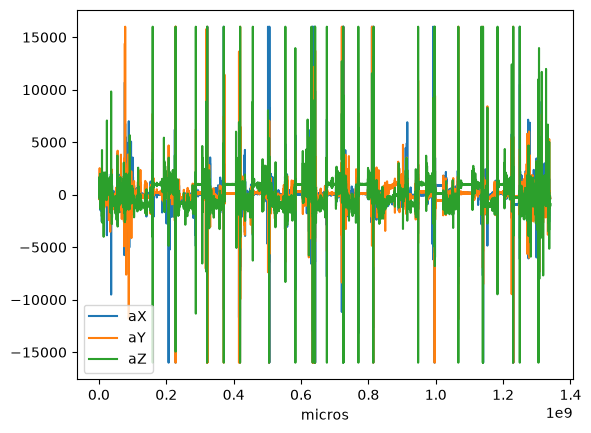

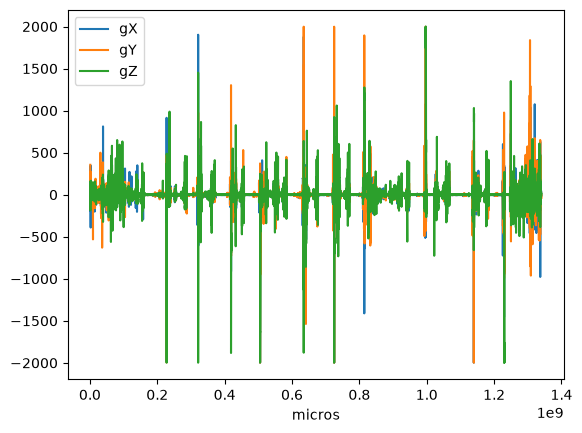

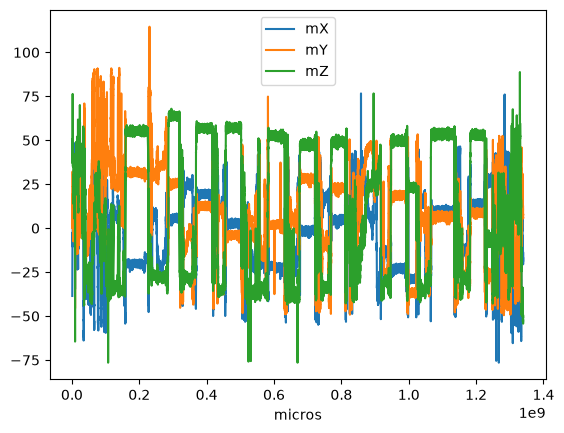

In [3]:
# Einlesen der Daten
FileNumber = 22 # Nummer der Messung
path = f"D:\\dataLog{FileNumber:>05}.TXT" #path
path  = r"C:\Users\oskar\Desktop\11__10_12Uhr_Druckreihe.TXT"


messdaten = pd.read_csv(path)
# messdaten["time"] = pd.to_datetime(messdaten["rtcDate"] + " " + messdaten["rtcTime"])
messdaten.drop(columns={'imu_degC', "rtcDate", "rtcTime", "micros"}, errors="ignore")
messdaten.drop(messdaten.columns[messdaten.columns.str.contains(
    'unnamed', case=False)], axis=1, inplace=True, errors="ignore")
messdaten["absA"] = np.sqrt(messdaten["aX"]**2 + messdaten["aY"]**2 + messdaten["aZ"]**2)


print(messdaten.head())

messdaten.plot(x="micros", y=["aX", "aY", "aZ"])
messdaten.plot(x="micros", y=["gX", "gY", "gZ"])
messdaten.plot(x="micros", y=["mX", "mY", "mZ"])
# messdaten.plot(x="micros", y="absA")

<Axes: xlabel='micros'>

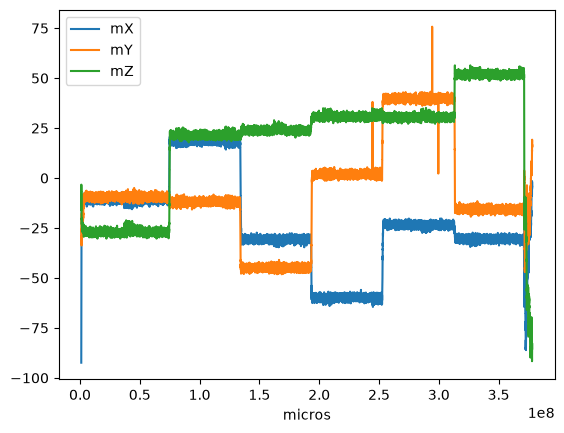

In [ ]:
# Einlesen der Daten
Zeiten = [["00:00:03", "00:01:09", "Z-"],
          ["00:01:13", "00:02:22", "X-"],
          ["00:02:44", "00:03:24", "Y+"],
          ["00:03:27", "00:04:16", "X+"],
          ["00:04:25", "00:05:22", "Y-"],
          ["00:05:28", "00:06:30", "Z+"]]

path = r"C:\Users\oskar\Desktop\olaKallibrierung\Kalibration.TXT" #path

messdaten = pd.read_csv(path)
messdaten.drop(columns={'imu_degC', "rtcDate", "rtcTime"}, errors="ignore")
messdaten.drop(messdaten.columns[messdaten.columns.str.contains('unnamed', case=False)], axis=1, inplace=True, errors="ignore")

messdaten_plot = None
messdaten["pose"] = None

# for start, end, pose in Zeiten:
#     mask = messdaten["micros"].dt.time.between(pd.Timestamp(start).time(), pd.Timestamp(end).time())
#     messdaten.loc[mask, "pose"] = pose
#     messdaten_plot = pd.concat([messdaten_plot, messdaten[mask]], ignore_index=True)

# mask = messdaten["time"].dt.time.between(pd.Timestamp("00:05:28").time(), pd.Timestamp("00:06:30").time())
# mask = messdaten["micros"].between(10, 10000)
# messdaten = messdaten[mask]

# messdaten.to_csv(r"C:\Users\oskar\Desktop\olaKallibrierung\data_for_kalibration.TXT")

messdaten.plot(x="micros", y=["mX", "mY", "mZ"])

<Axes: xlabel='time'>

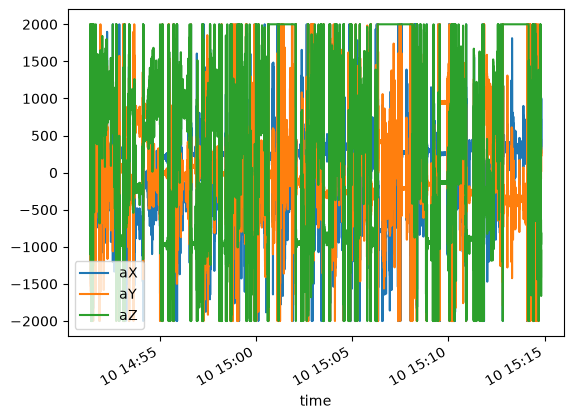

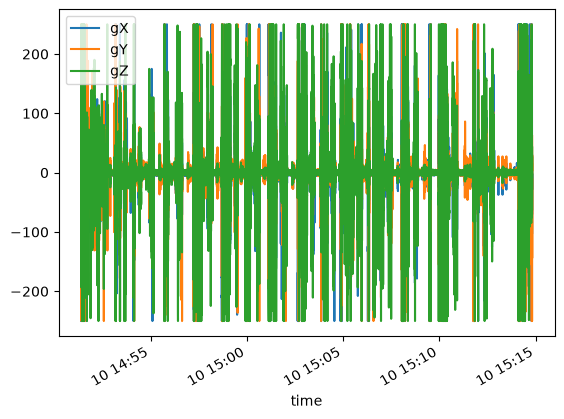

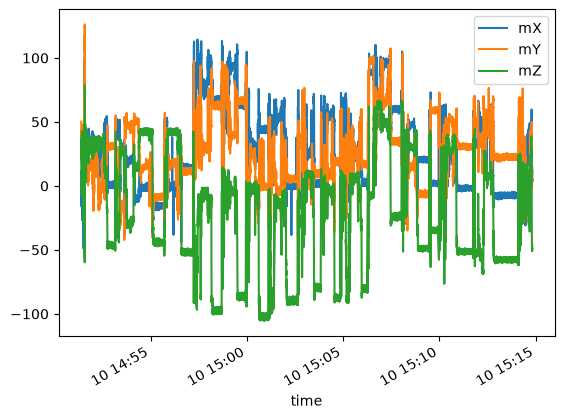

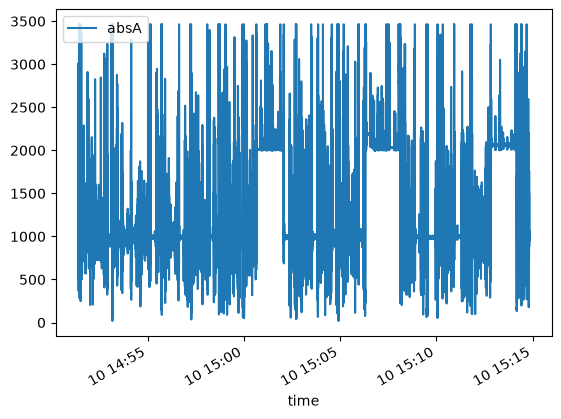

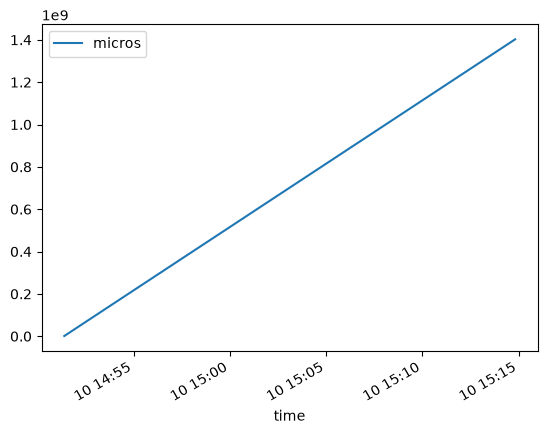

In [41]:
# Einlesen der Daten
# 0-11 erstes Set.
messdaten = None


for i in range(0, 11):
    path = f"D:\\dataLog{i:>05}.TXT" #path

    inData = pd.read_csv(path)
    inData["time"] = pd.to_datetime(inData["rtcDate"] + " " + inData["rtcTime"])
    inData.drop(columns={'imu_degC', "rtcDate", "rtcTime", "micros"}, errors="ignore")
    inData.drop(inData.columns[inData.columns.str.contains(
        'unnamed', case=False)], axis=1, inplace=True, errors="ignore")
    inData["absA"] = np.sqrt(inData["aX"]**2 + inData["aY"]**2 + inData["aZ"]**2)    

    messdaten = pd.concat([messdaten, inData], ignore_index=True)

# Eigene Frequenz berechnen 
# t in ms von startpunkt ab restliche Zeit löschen Date Time braucht man eigetnlich nicht?


mask = messdaten["time"].dt.time.between(pd.Timestamp("15:15:15").time(), pd.Timestamp("17:00:00").time())
# messdaten = messdaten[mask]

messdaten.plot(x="time", y=["aX", "aY", "aZ"])
messdaten.plot(x="time", y=["gX", "gY", "gZ"])
messdaten.plot(x="time", y=["mX", "mY", "mZ"])
messdaten.plot(x="time", y="absA")
messdaten.plot(x="time", y="micros")



9.944922280821038
Index(['rtcDate', 'rtcTime', 'micros', 'aX', 'aY', 'aZ', 'gX', 'gY', 'gZ',
       'mX', 'mY', 'mZ', 'imu_degC', 'output_Hz', 'time', 'absA'],
      dtype='str')


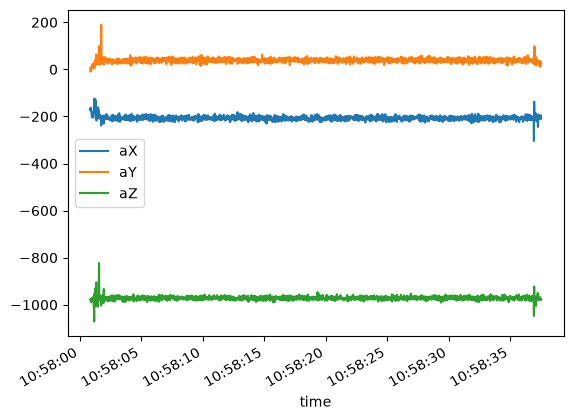

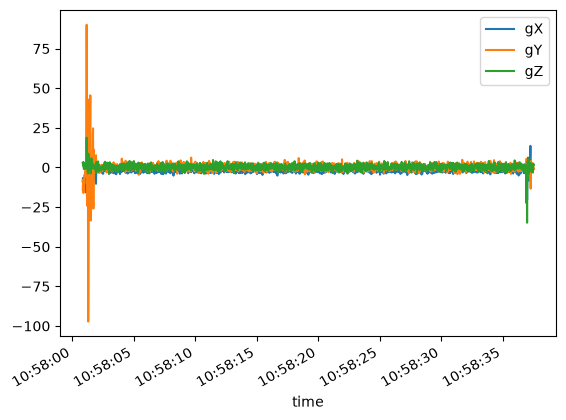

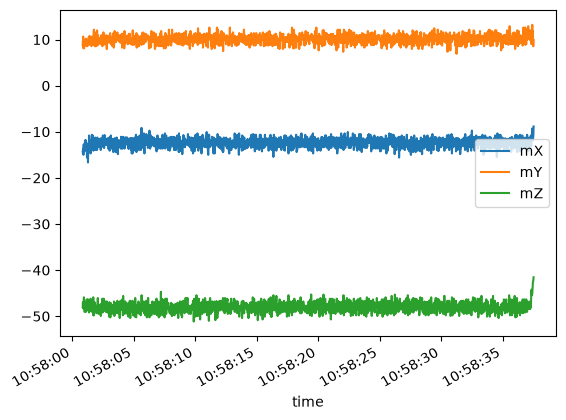

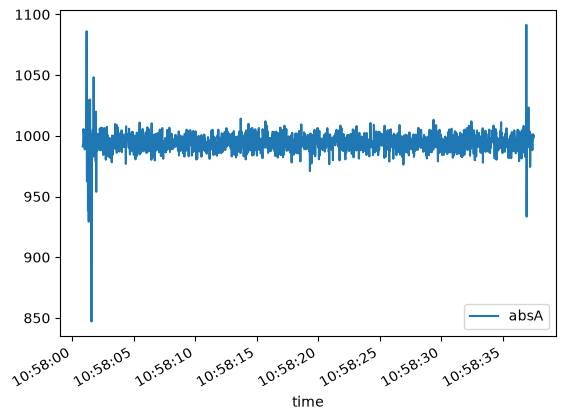

In [4]:
path = f"Messung01.txt" #path

messdaten = pd.read_csv(path)
messdaten["time"] = pd.to_datetime(messdaten["rtcDate"] + " " + messdaten["rtcTime"])
messdaten.drop(columns={'imu_degC', "rtcDate", "rtcTime", "micros"}, errors="ignore")
messdaten.drop(messdaten.columns[messdaten.columns.str.contains(
    'unnamed', case=False)], axis=1, inplace=True, errors="ignore")
messdaten["absA"] = np.sqrt(messdaten["aX"]**2 + messdaten["aY"]**2 + messdaten["aZ"]**2)

messdaten.plot(x="time", y=["aX", "aY", "aZ"])
messdaten.plot(x="time", y=["gX", "gY", "gZ"])
messdaten.plot(x="time", y=["mX", "mY", "mZ"])
messdaten.plot(x="time", y="absA")

print(np.mean(messdaten["absA"])/100)

print(messdaten.columns)